### TP de clasificacion - Prediccion de lluvia en Australia
#### Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA - UNR)
Integrantes: Aguirre, Gambande, Paladini

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import warnings 
warnings.filterwarnings('ignore')

# Configuración global de visualización (consistencia entre gráficos)
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 100
})
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42  # semilla fija para reproducibilidad

In [111]:
df = pd.read_csv("data/weatherAUS_2026C2.csv")

### Consigna 1

### Inspeccion del dataset

In [112]:
#Revisamos el dataset para verificar tipos de datos y faltantes 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

In [113]:
df.columns

Index(['Unnamed: 0', 'Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall',
       'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am',
       'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow', 'RainfallTomorrow'],
      dtype='str')

In [114]:
df

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145407,145454,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,...,26.5,1024.8,1021.2,NaN,NaN,10.1,21.6,No,No,0.0
145408,145455,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,...,24.7,1024.3,1020.5,NaN,NaN,11.1,21.5,No,No,0.0
145409,145456,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,...,21.4,1023.3,1018.4,NaN,NaN,11.8,24.5,No,No,0.0
145410,145457,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,...,23.7,1021.0,1016.0,NaN,NaN,12.0,26.9,No,No,0.0


### 1.1 Análisis y decisión sobre datos faltantes

In [115]:
# Observamos que la columna Date se encontraba como tipo str. Ante esto, se decide convertirla a datetime.
df["Date"] = pd.to_datetime(df["Date"])

In [116]:
# Se decide elimininar la columna 'Unnamed: 0' ya que solo representaba indices dentro del dataset.
df = df.drop(columns = ['Unnamed: 0'])

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Date              145412 non-null  datetime64[us]
 1   Location          145412 non-null  str           
 2   MinTemp           143928 non-null  float64       
 3   MaxTemp           144159 non-null  float64       
 4   Rainfall          142152 non-null  float64       
 5   Evaporation       82658 non-null   float64       
 6   Sunshine          75616 non-null   float64       
 7   WindGustDir       135096 non-null  str           
 8   WindGustSpeed     135159 non-null  float64       
 9   WindDir9am        134850 non-null  str           
 10  WindDir3pm        141186 non-null  str           
 11  WindSpeed9am      143645 non-null  float64       
 12  WindSpeed3pm      142351 non-null  float64       
 13  Humidity9am       142759 non-null  float64       
 14  Humidity3pm    

In [118]:
# Mostramos el porcentaje de nulos de cada variable respecto al total y la cantidad de faltantes en cada variable
nulos = df.isnull().sum()
porcentaje_nulos = (nulos / len(df)) * 100

reporte_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos.round(2)})
reporte_nulos = reporte_nulos[reporte_nulos['Nulos'] > 0].sort_values('Nulos', ascending=False)
reporte_nulos

,Nulos,Porcentaje (%)
Sunshine,69796,48.00
Evaporation,62754,43.16
Cloud3pm,59336,40.81
Cloud9am,55870,38.42
Pressure9am,15061,10.36
Pressure3pm,15024,10.33
WindDir9am,10562,7.26
WindGustDir,10316,7.09
WindGustSpeed,10253,7.05
Humidity3pm,4505,3.10


In [119]:
# Distribución de filas según cantidad y porcentaje de columnas faltantes
nulos_por_fila = df.isnull().sum(axis=1)
dist = nulos_por_fila.value_counts().sort_index().to_frame('Filas')
dist['% columnas faltantes'] = (dist.index / df.shape[1] * 100).round(1)
dist

,Filas,% columnas faltantes
0,56412,0.0
1,10764,4.2
2,18167,8.3
3,9920,12.5
4,28702,16.7
5,3774,20.8
6,10432,25.0
7,2087,29.2
8,1440,33.3
9,500,37.5


Se observa que la variable target (RainTomorrow) posee 3259 valores faltantes, lo que equivale aproximadamente a 2.24% de los valores faltantes. Como imputar la variable target implicaria tener datos artificiales en nuestra prediccion, se decide eliminar esas filas en lugar de imputarlas.

In [124]:
df = df.dropna(subset= ["RainTomorrow"])

In [154]:
df.info()

<class 'pandas.DataFrame'>
Index: 142153 entries, 0 to 145411
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Date              142153 non-null  datetime64[us]
 1   Location          142153 non-null  str           
 2   MinTemp           141516 non-null  float64       
 3   MaxTemp           141831 non-null  float64       
 4   Rainfall          140747 non-null  float64       
 5   Evaporation       81341 non-null   float64       
 6   Sunshine          74368 non-null   float64       
 7   WindGustDir       132825 non-null  str           
 8   WindGustSpeed     132885 non-null  float64       
 9   WindDir9am        132144 non-null  str           
 10  WindDir3pm        138377 non-null  str           
 11  WindSpeed9am      140805 non-null  float64       
 12  WindSpeed3pm      139524 non-null  float64       
 13  Humidity9am       140379 non-null  float64       
 14  Humidity3pm       13

Volvemos a recalcular los faltantes despues de eliminar filas con mas de 50% de faltantes

In [146]:
# Eliminar filas con mas del 50% de columnas faltantes
pct_nulos_fila = df.isnull().sum(axis=1) / df.shape[1] * 100
df = df[pct_nulos_fila <= 50]

In [147]:
nulos = df.isnull().sum()
porcentaje_nulos = (nulos / len(df)) * 100

reporte_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos.round(2)})
reporte_nulos = reporte_nulos[reporte_nulos['Nulos'] > 0].sort_values('Nulos', ascending=False)
reporte_nulos

,Nulos,Porcentaje (%)
Sunshine,67448,47.57
Evaporation,60484,42.66
Cloud3pm,56736,40.01
Cloud9am,53344,37.62
Pressure9am,13685,9.65
Pressure3pm,13658,9.63
WindDir9am,9662,6.81
WindGustDir,9039,6.37
WindGustSpeed,8979,6.33
WindDir3pm,3462,2.44


In [148]:
nulos_por_fila = df.isnull().sum(axis=1)
dist = nulos_por_fila.value_counts().sort_index().to_frame('Filas')
dist['% columnas faltantes'] = (dist.index / df.shape[1] * 100).round(1)
dist

,Filas,% columnas faltantes
0,56412,0.0
1,10764,4.2
2,18023,8.3
3,9607,12.5
4,28531,16.7
5,3639,20.8
6,9934,25.0
7,1801,29.2
8,964,33.3
9,393,37.5


In [144]:
target = df["RainTomorrow"]

variables_numericas = df.select_dtypes(include="number").columns.tolist()
variables_categoricas = df.select_dtypes(include="object").columns.tolist()

# Sacamos la target de categóricas
variables_categoricas.remove("RainTomorrow")

In [149]:
descripcion = df[variables_numericas].describe().T
descripcion["sesgo"] = df[variables_numericas].skew()
descripcion["curtosis"] = df[variables_numericas].kurtosis()
descripcion

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
MinTemp,141421.0,12.190938,6.421817,-9.7,7.6,12.0,16.8,34.1,0.022692,-0.481890
MaxTemp,141573.0,23.234478,7.130074,-5.1,17.9,22.6,28.2,49.1,0.226728,-0.242386
Rainfall,140513.0,2.352009,8.471265,0.0,0.0,0.0,0.8,371.0,9.884421,179.820367
Evaporation,81310.0,5.470054,4.188881,0.0,2.6,4.8,7.4,145.0,3.747456,45.074191
Sunshine,74346.0,7.624681,3.781586,0.0,4.9,8.5,10.6,14.5,-0.503016,-0.820337
WindGustSpeed,132815.0,39.984655,13.630224,6.0,31.0,38.0,48.0,135.0,0.866628,1.401613
WindSpeed9am,140743.0,14.029721,8.912229,0.0,7.0,13.0,19.0,130.0,0.785859,1.222164
WindSpeed3pm,139470.0,18.638653,8.858088,0.0,12.0,18.0,24.0,86.0,0.620194,0.741050
Humidity9am,140313.0,68.819894,19.084458,0.0,56.9,69.9,83.1,100.0,-0.484703,-0.044114
Humidity3pm,138485.0,51.472381,20.844515,0.0,36.5,51.9,65.6,100.0,0.032106,-0.509787


## Analisis de variables numericas

### Distribucion de las variables numericas

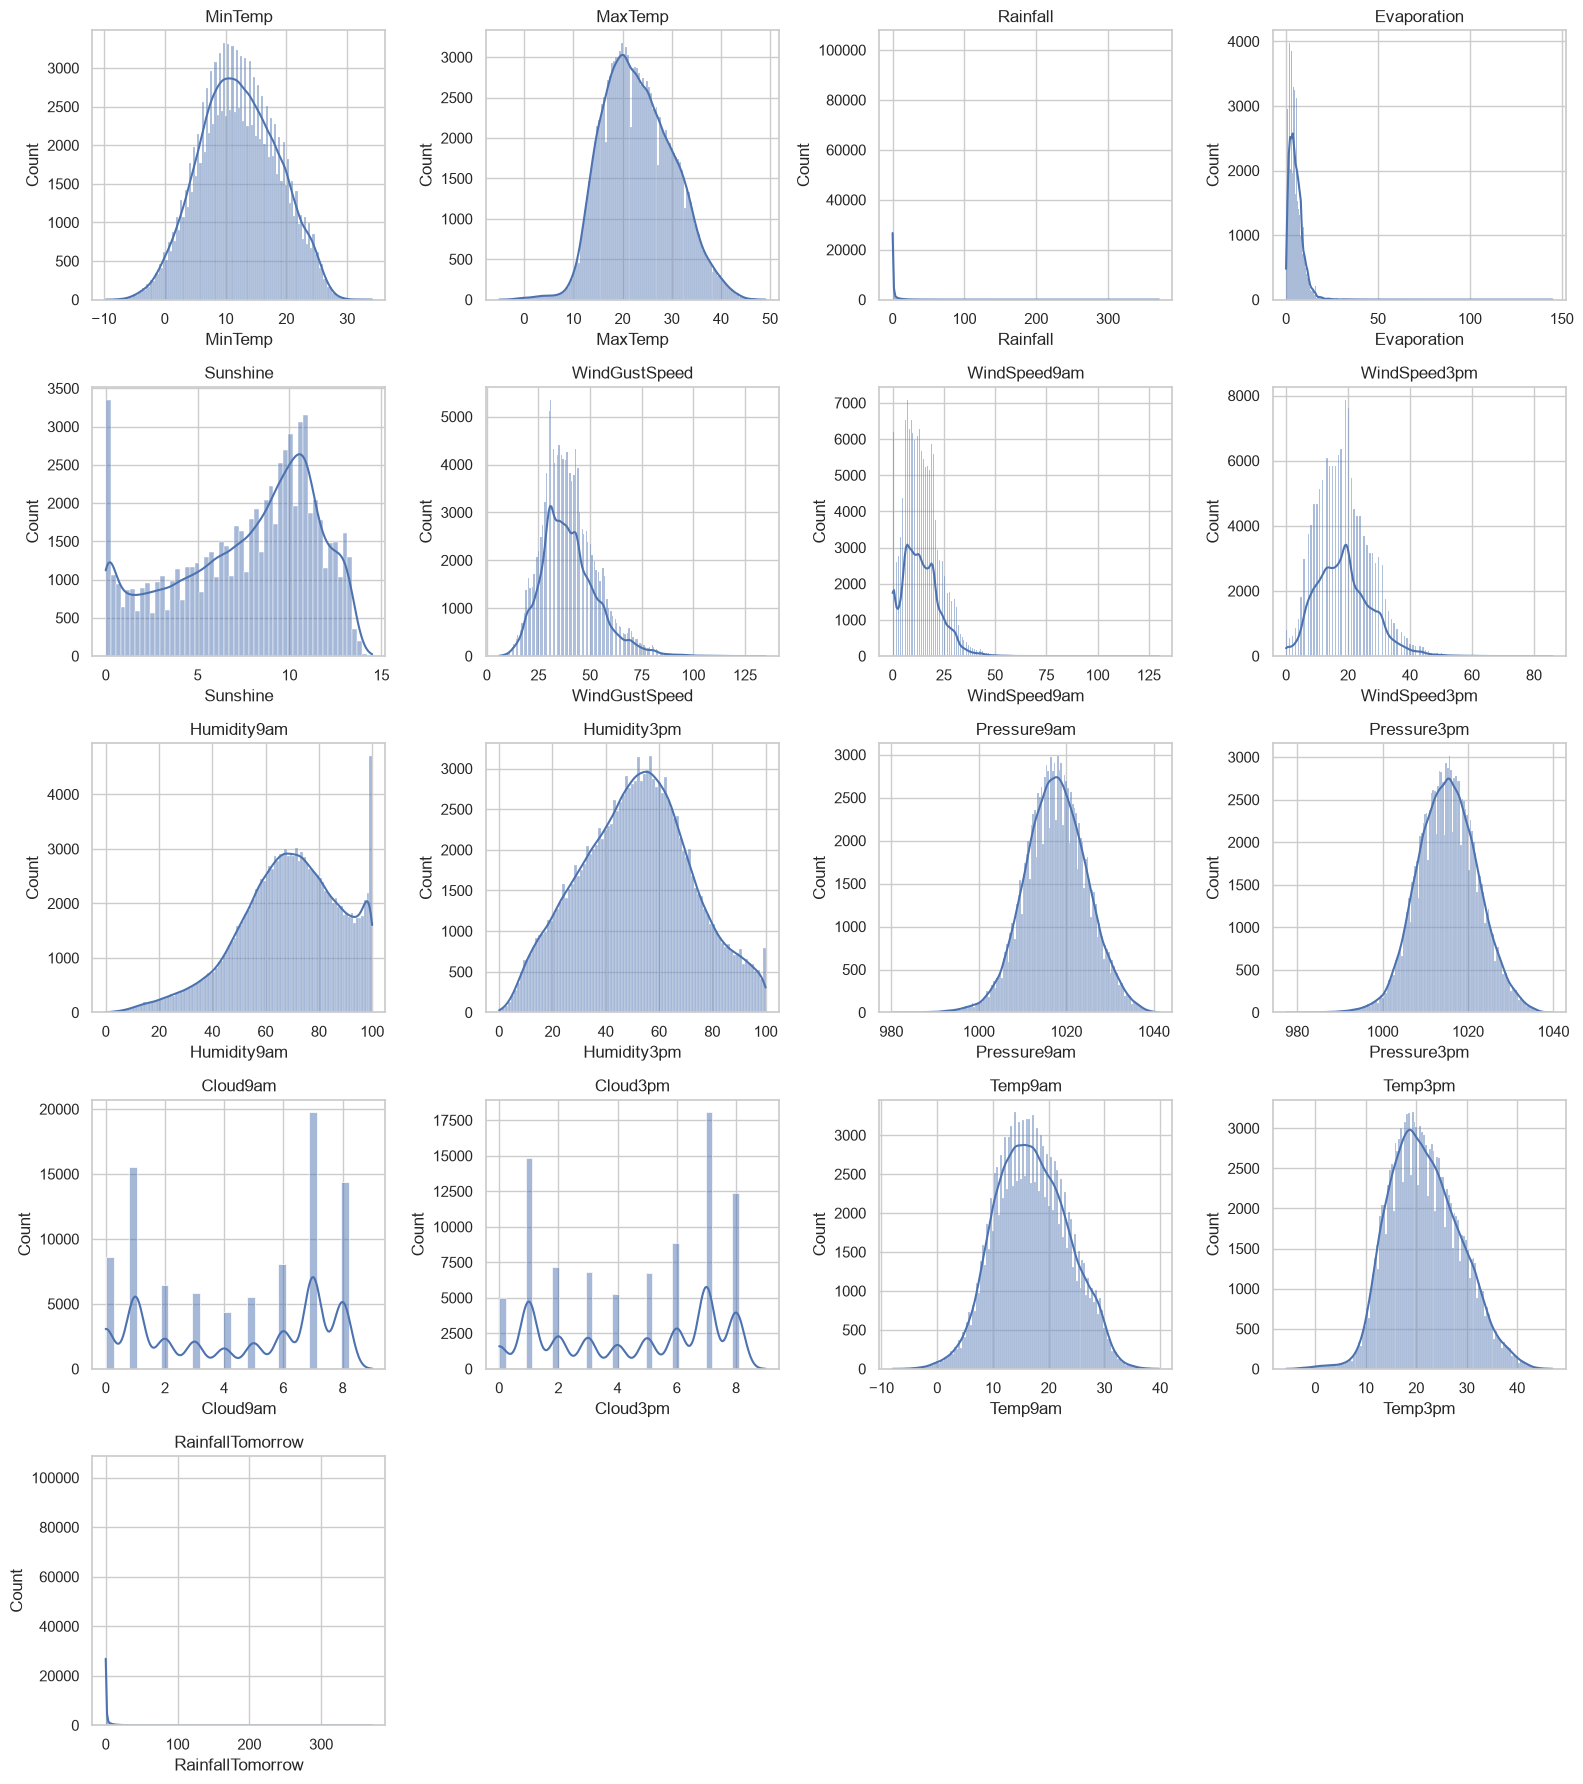

In [150]:
fig, axes = plt.subplots(5, 4, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(col)

for j in range(len(variables_numericas), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Distribucion y valores atipicos de variables numericas

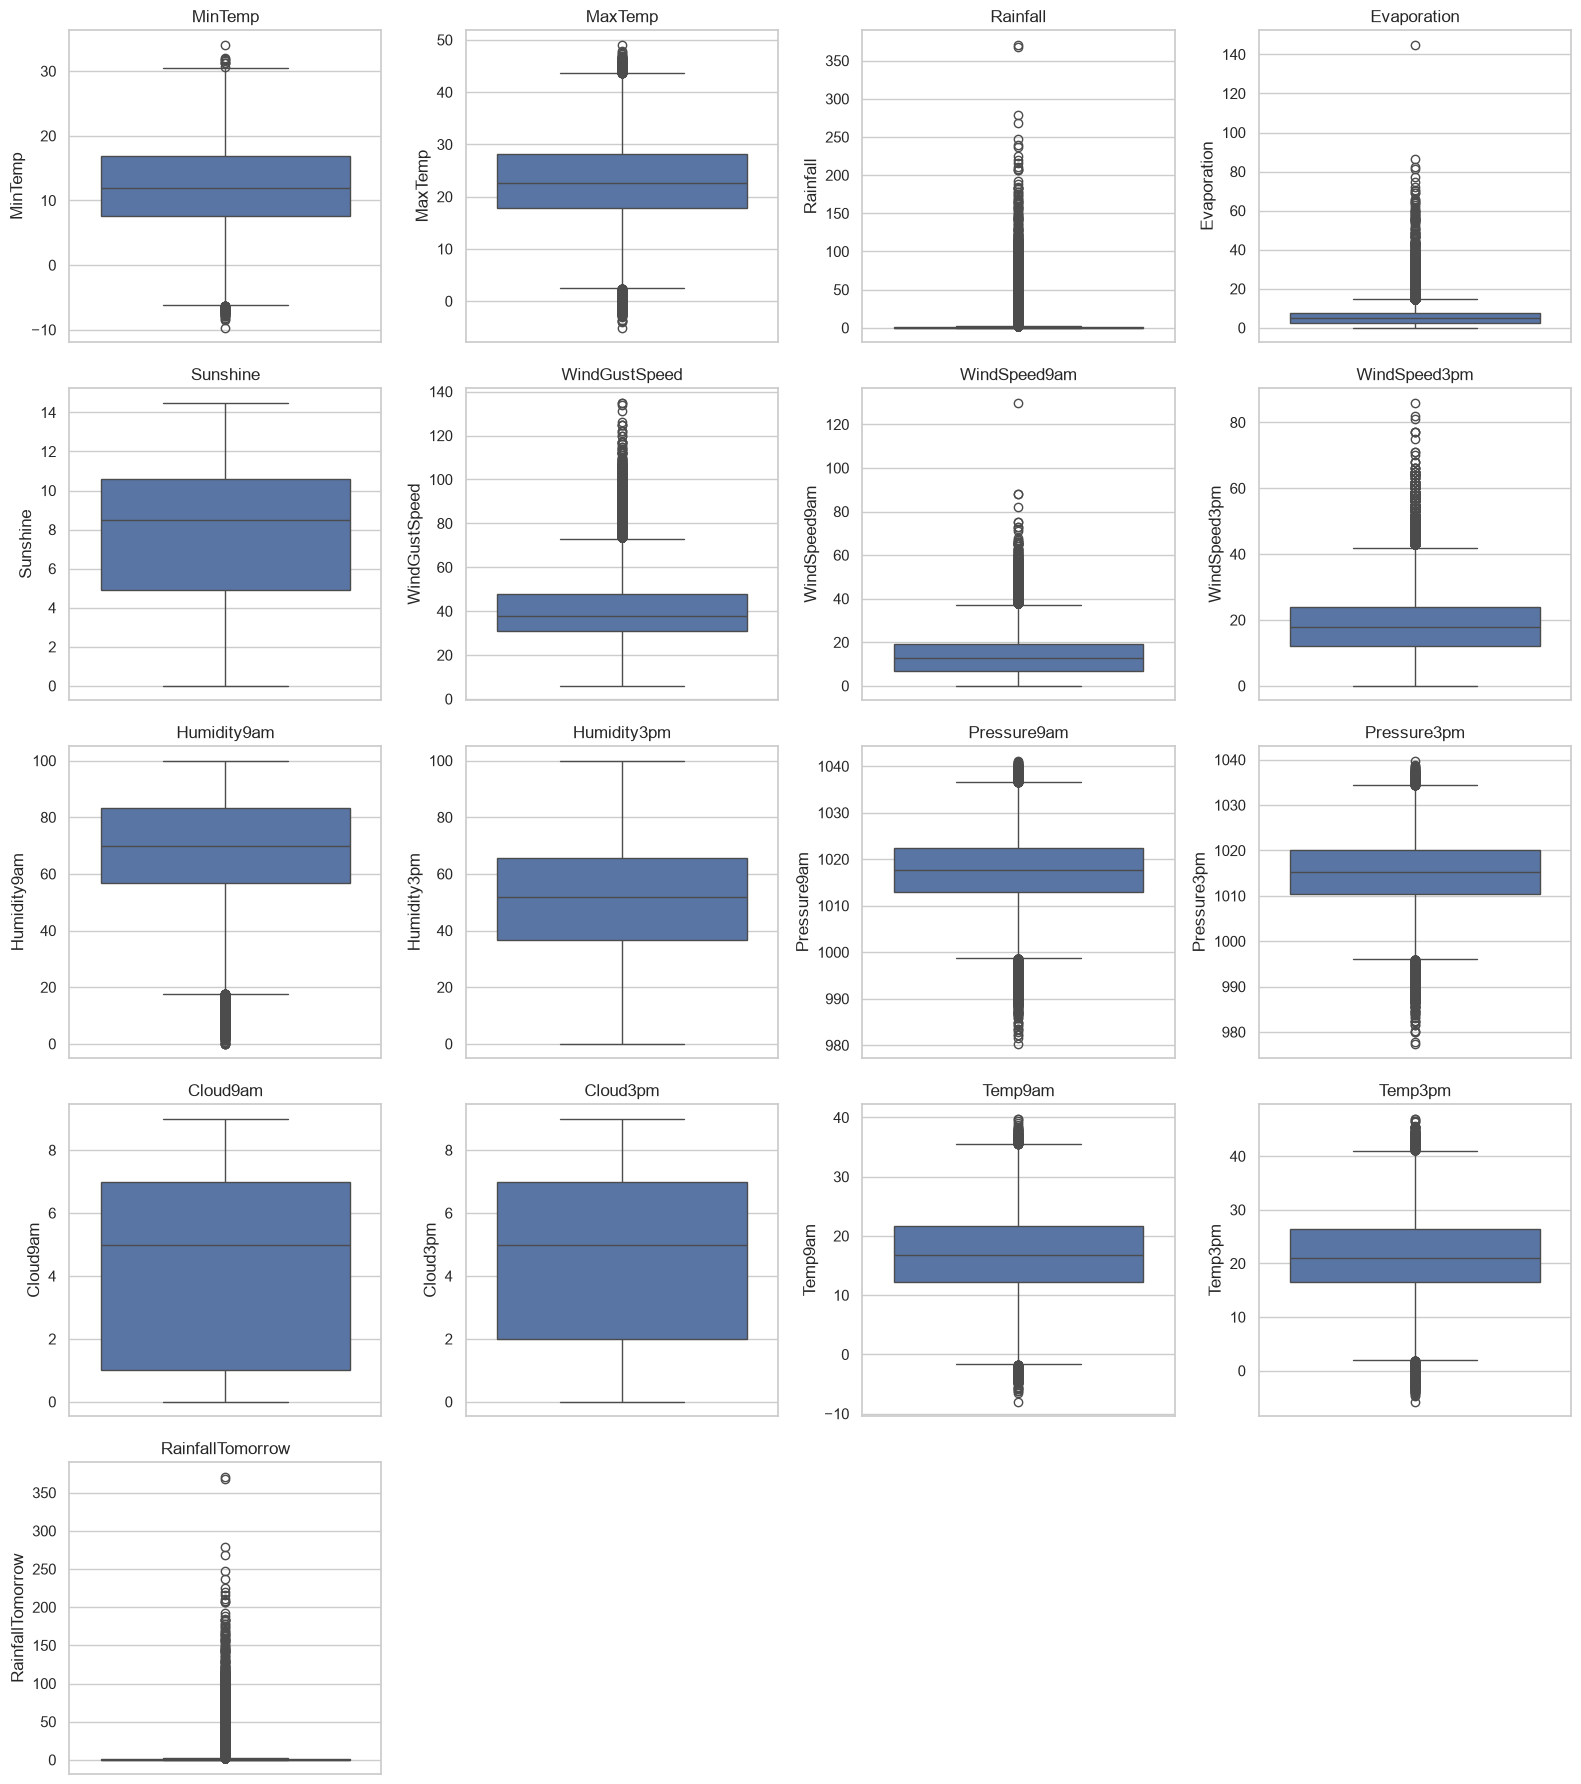

In [154]:
fig, axes = plt.subplots(5, 4, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    sns.boxplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(variables_numericas), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Mapa de correlacion

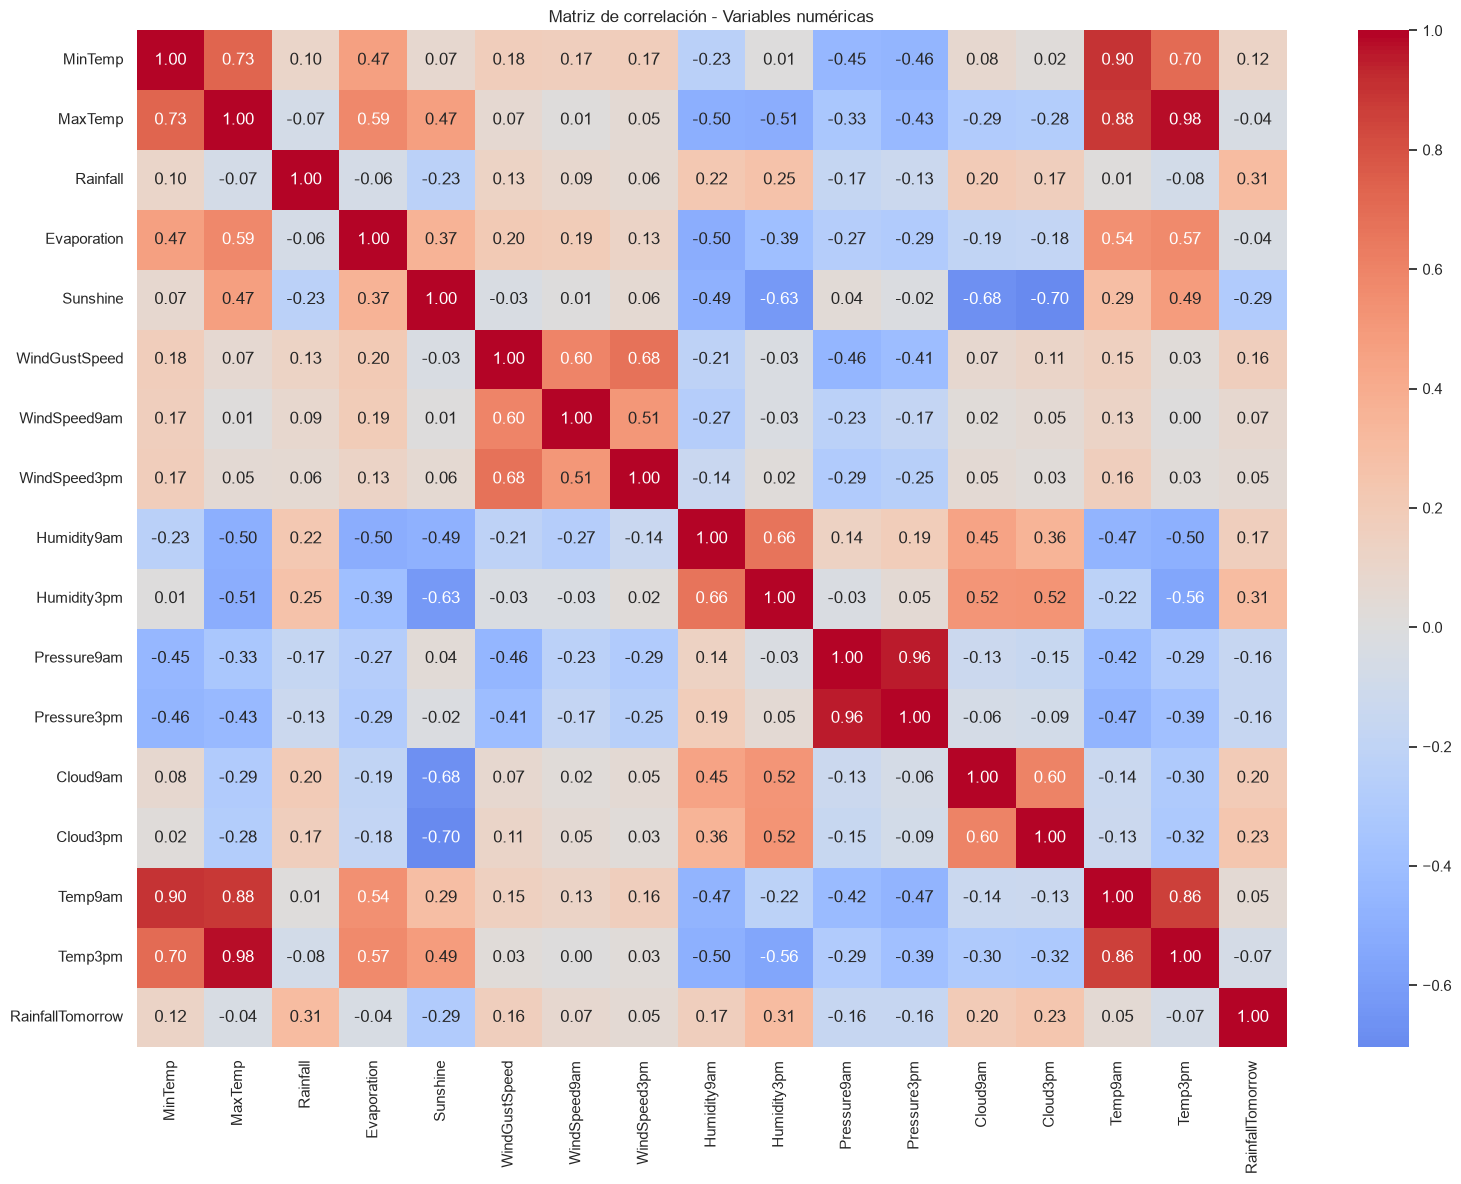

In [155]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    df[variables_numericas].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación - Variables numéricas")
plt.tight_layout()
plt.show()

### Calculo de outliers en variables numericas

In [156]:
outliers = {}

for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    cantidad = df[
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    ].shape[0]

    outliers[col] = cantidad

outliers

{'MinTemp': 60,
 'MaxTemp': 474,
 'Rainfall': 25194,
 'Evaporation': 1954,
 'Sunshine': 0,
 'WindGustSpeed': 2897,
 'WindSpeed9am': 1891,
 'WindSpeed3pm': 1662,
 'Humidity9am': 1425,
 'Humidity3pm': 0,
 'Pressure9am': 1181,
 'Pressure3pm': 915,
 'Cloud9am': 0,
 'Cloud3pm': 0,
 'Temp9am': 254,
 'Temp3pm': 744,
 'RainfallTomorrow': 25492}

## Analisis de variables categoricas

In [157]:
for col in variables_categoricas:
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100)

Location
Canberra            3411
Sydney              3336
Perth               3192
Darwin              3192
Hobart              3187
Brisbane            3160
Adelaide            3089
Bendigo             3033
Townsville          3032
AliceSprings        3031
MountGambier        3029
Launceston          3027
Ballarat            3025
Albury              3010
MelbourneAirport    3008
PerthAirport        3008
Mildura             3006
SydneyAirport       3004
Nuriootpa           3002
Sale                2999
Watsonia            2998
Tuggeranong         2995
Portland            2995
Woomera             2990
Cairns              2987
Cobar               2984
Albany              2983
Wollongong          2982
GoldCoast           2979
WaggaWagga          2975
NorfolkIsland       2963
Penrith             2959
SalmonGums          2952
Witchcliffe         2950
CoffsHarbour        2946
Richmond            2944
Dartmoor            2941
NorahHead           2926
BadgerysCreek       2923
Moree           

### Distribucion de las variables categoricas

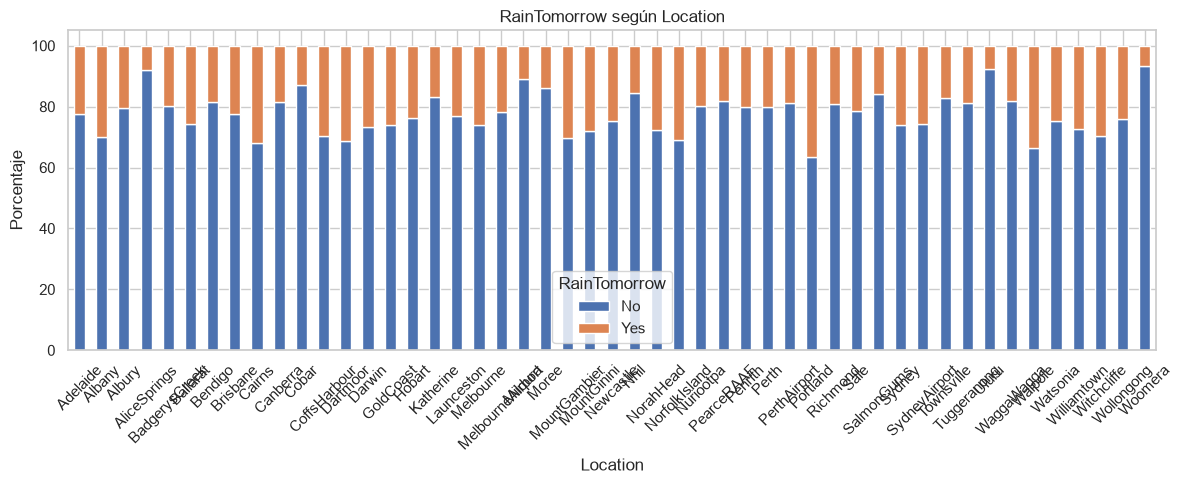

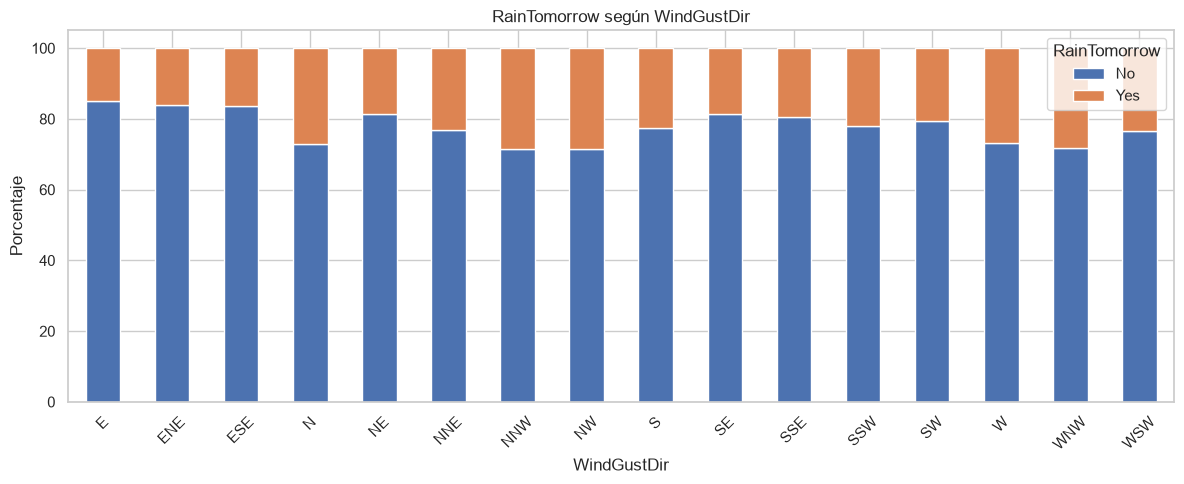

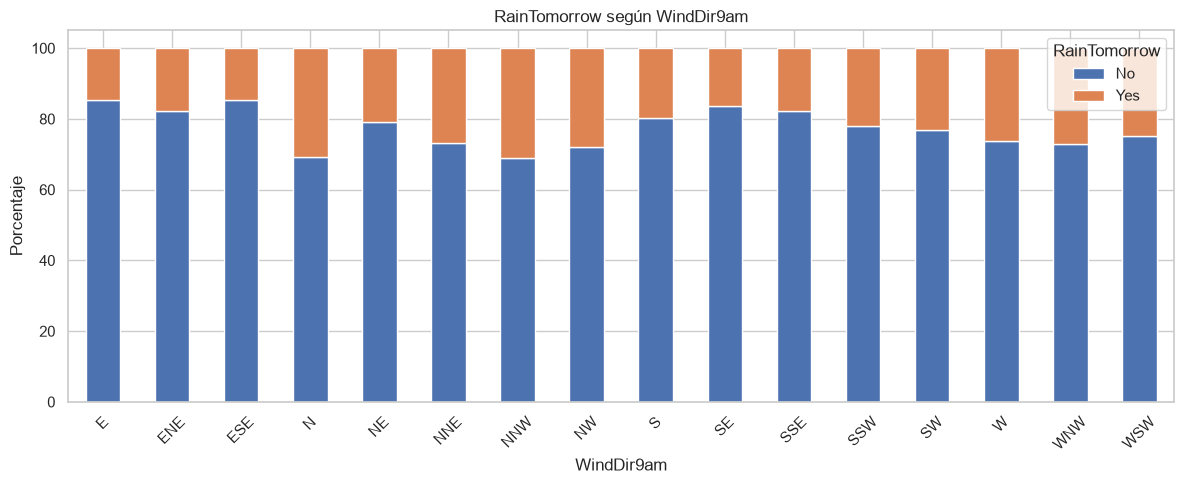

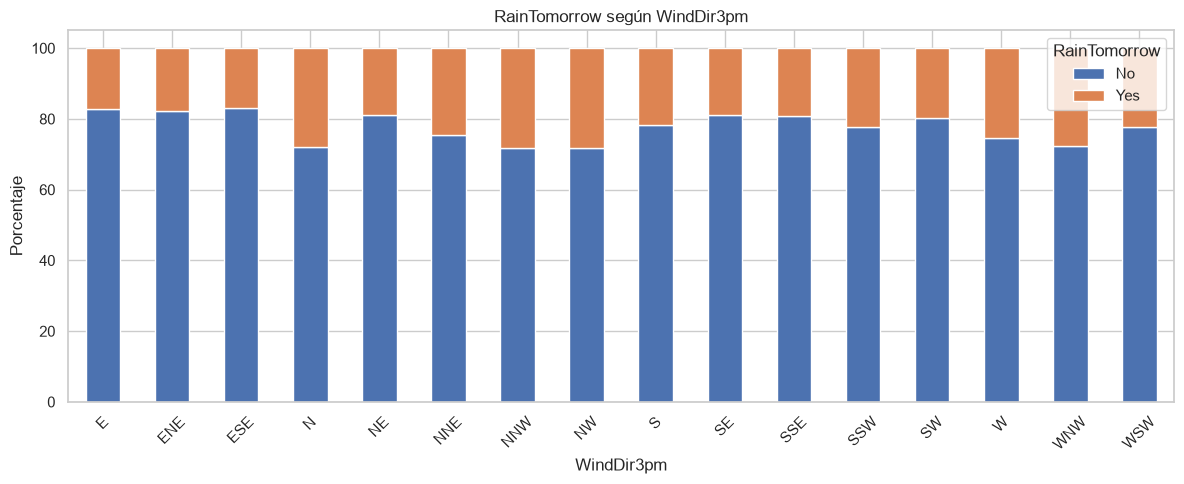

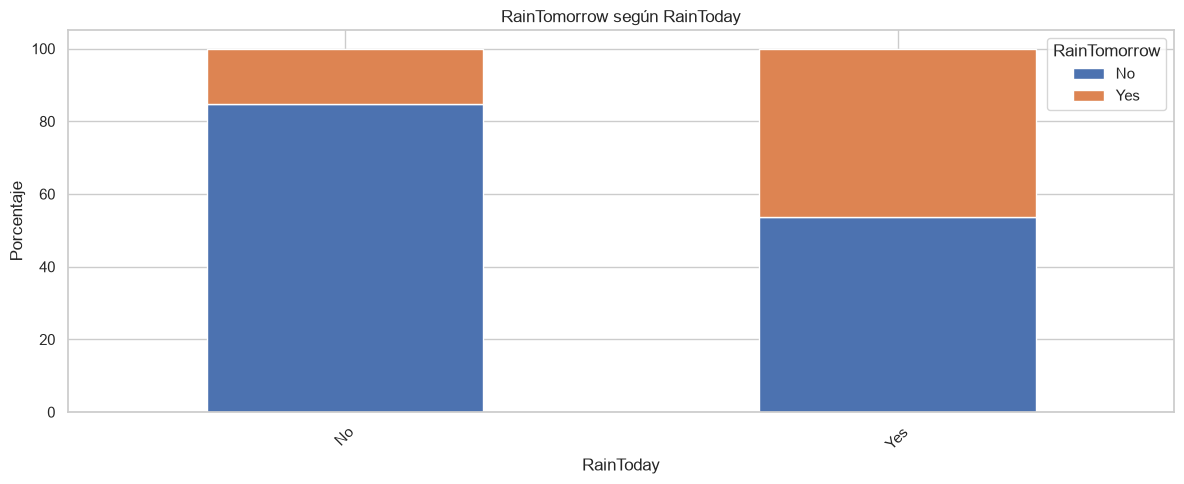

In [168]:
for col in variables_categoricas:
    
    tabla = pd.crosstab(
        df[col],
        df["RainTomorrow"],
        normalize="index"
    ) * 100

    tabla.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 5)
    )

    plt.title(f"RainTomorrow según {col}")
    plt.ylabel("Porcentaje")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.legend(title="RainTomorrow")
    plt.tight_layout()
    plt.show()

Se compara cada variable con la variable objetivo RainTomorrow para ver si algunas categorias tienen mayor o menor proporcion de lluvia al dia siguiente.

### Analisis de la variable objetivo (RainTomorrow)

In [163]:
df["RainTomorrow"].value_counts(normalize= True) * 100

RainTomorrow
No     77.59073
Yes    22.40927
Name: proportion, dtype: float64

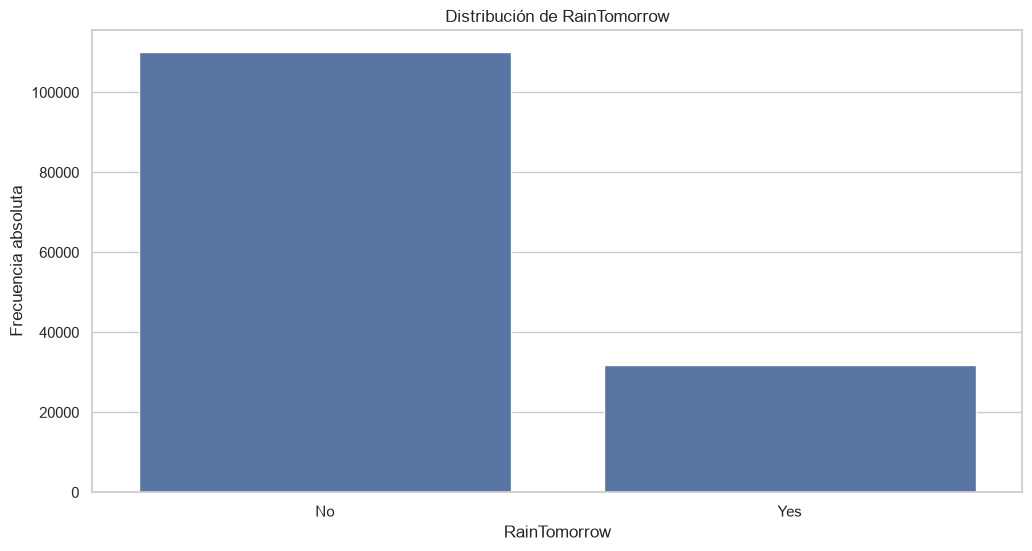

In [167]:
sns.countplot(data=df, x="RainTomorrow")
plt.title("Distribución de RainTomorrow")
plt.ylabel("Frecuencia absoluta")
plt.show()

La variable se encuentra desproporcionada, aproximadamente 78% de las observaciones son NO, mientras que alrededor del 22% de las mismas dice que SI llovera mañana.
Este desbalance en la variable es importante para analizar el modelo porque que predomine la respuesta "NO" puede hacer que un modelo tienda a favorecer a esta clase mayoritaria dando una precision aparentemente alta pero erronea detectando mal los dias de lluvia.

### Analisis extra sobre la variable RainfallTomorrow

In [172]:
df["RainfallTomorrow"].value_counts(normalize=True)

RainfallTomorrow
0.0      0.640556
0.2      0.061660
0.4      0.026588
0.6      0.018252
0.8      0.014429
           ...   
210.6    0.000007
117.6    0.000007
69.5     0.000007
167.0    0.000007
69.0     0.000007
Name: proportion, Length: 678, dtype: float64

Esta variable numerica representa cuanta lluvia caera al dia siguiente, la cual esta relacionada a la variable Target que predice si llueve o no al dia siguiente. Se la analiza aparte ya que es muy sospechosa de data leakage, ya que si voy a predecir si mañana llovera o no, no deberia saber previamente cuantos mm caeran al dia siguiente. Es una variable candidata a ser eliminada.

## Decision sobre imputacion de datos